# TERZ net comparison: embeddings + density + clustering

For every (year, `ont`) combination this notebook:

1. loads the TERZ parquet, normalises each trigger by its max and standardises the features (same preprocessing as `net_compare_cut.ipynb`),
2. computes a t-SNE and a UMAP embedding (cached on disk, so the slow part only runs once),
3. draws **one 2x2 figure per projection**: embedding scatter, KDE density, k-means (centroids at the KDE peaks), HDBSCAN (the logic of `density.ipynb`),
4. (last section) draws `PER_CLUSTER` random triggers from every cluster (**HDBSCAN** by default, `LABEL_METHOD`) and computes t-SNE and UMAP again on that balanced subset, coloured by the first-round cluster label,
5. (last section) draws a **map of spectrogram thumbnails** on the subset embeddings, to look at what the clusters contain.

Half-width window is 12 s (`hw12`), as in `net_compare_cut.ipynb`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import re
from PIL import Image
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from matplotlib.patches import Patch
from scipy.ndimage import maximum_filter
from scipy.stats import gaussian_kde
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances_argmin
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
METRIC = "euclidean"

PARQUET_DIR = Path("year_TERZ_parquets")
CACHE_DIR = Path("TERZ_embeddings_cache")      # embeddings are stored here
CACHE_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("TERZ_figures_net_compare_sampling")
SAVE_FIGS = True                         # True -> also save every figure as a PNG in FIG_DIR

# What to run. net_compare_cut.ipynb only processed 2022; add the other years here.
YEARS = [2022]                            # e.g. [2022, 2023, 2024, 2025]
ONTS = [25] #[15, 20, 25]
HW = [6,12] #[1, 2, 4, 6, 12]                       

# t-SNE (same values as net_compare_cut.ipynb)
PERPLEXITY = 350
EARLY_EXAGGERATION = 14

# UMAP -- placeholders, set these to the values you used in mn-sena-splited.ipynb
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1

# Clustering parameters (see the note below the cell)
#   kde_peak_size:       a KDE grid point is a peak if it is the maximum of its size x size window (grid cells)
#   kde_peak_min_rel:    peaks lower than this fraction of the tallest peak are ignored
#   hdbscan_min_samples: carried over from density.ipynb
CLUSTER_PARAMS = {
    "tsne": {"kde_peak_size": 15, "kde_peak_min_rel": 0.05, "hdbscan_min_samples": 500},
    "umap": {"kde_peak_size": 15, "kde_peak_min_rel": 0.05, "hdbscan_min_samples": 500},
}
# Per-dataset overrides, keyed by (year, ont, projection), e.g.
# CLUSTER_OVERRIDES = {(2022, 15, "umap"): {"kde_peak_min_rel": 0.1}}
CLUSTER_OVERRIDES = {}

# k-means: one cluster per KDE peak, the peaks are the centroids.
# False -> centroids stay exactly on the KDE peaks; every point goes to its nearest peak.
# True  -> the peaks are only the starting centroids; k-means (Lloyd iterations) then moves them.
KMEANS_REFINE = False

# Density panel
DENSITY_3D = True                         # True: 3D surface as in density.ipynb, False: 2D filled contours
GRID_SIZE = 200                           # density.ipynb used 500; 200 is ~6x faster to evaluate

PROJECTIONS = {"tsne": "t-SNE", "umap": "UMAP"}

# Balanced subset + second round of dimensionality reduction
LABEL_FROM = "tsne"                       # projection whose clusters are the labels: "tsne" or "umap"
LABEL_METHOD = "hdbscan"                  # clustering that defines the groups to sample from: "hdbscan" or "kmeans"
INCLUDE_NOISE = False                     # HDBSCAN only: True -> the noise points (label -1) are sampled as one more group
PER_CLUSTER = 750                        # triggers drawn at random from every cluster
MIN_CLUSTER_SIZE = PER_CLUSTER
SUBSET_DIR = Path("TERZ_subsets")         # selected row indices + labels are stored here
SUBSET_DIR.mkdir(exist_ok=True)
# embedding parameters for the subset 
SUB_PERPLEXITY = 15 #PERPLEXITY
SUB_EARLY_EXAGGERATION = EARLY_EXAGGERATION
SUB_UMAP_N_NEIGHBORS = UMAP_N_NEIGHBORS
SUB_UMAP_MIN_DIST = UMAP_MIN_DIST

# Spectrogram thumbnail map (last section)
THUMB_PDF_ROOT = "TERZ_HHZ_ont{ont}/TERZ_spectrograms_matrix_results_cut_hw{hw}_ont{ont}"   # searched recursively for the qtransform PDFs
                                          # ({year}, {ont}, {hw} are filled in; use a plain path if the PDFs are somewhere else)
THUMB_DATE_COLUMN = "date"                # parquet column with the day of each trigger (the PDF name starts with this date)
THUMB_TIME_COLUMN = "trigger_time"        # parquet column with the trigger time (ISO string, UTC); used when THUMB_ORDER = "time"
THUMB_ORDER = "parquet"                   # how the triggers of one day are numbered to find their PDF (qtransform_<date>_<counter>.pdf):
                                          # "parquet" = in parquet row order, "time" = sorted by THUMB_TIME_COLUMN
THUMB_PAGE = 1                            # 0-based PDF page: 0 = binned matrix, 1 = spectrogram (jet), 2 = "natural" colormap
THUMB_CROP = None                         # optional (left, top, right, bottom) fractions of the page to keep, e.g. (0.1, 0.08, 0.9, 0.92)
THUMB_PX = 96                             # longest side of a cached thumbnail, in pixels
THUMB_DPI = 40                            # resolution the PDF page is rendered at before shrinking
THUMB_CACHE = Path("TERZ_thumbs_cache")   # thumbnails are cached here as PNG
THUMB_CACHE.mkdir(exist_ok=True)
N_THUMBS = 400                            # at most this many thumbnails per map
THUMB_FILL = 0.9                          # thumbnail size as a fraction of its grid cell (1 = touching)
THUMB_BORDER = True                       # True -> coloured frame (cluster colour) around every thumbnail
THUMB_FIG_SIZE = 14                       # figure side, inches


**Clustering parameters.** The k-means panel takes both the number of clusters and the centroids from the peaks of the Gaussian KDE: a peak is a grid point that is the maximum of its `kde_peak_size` x `kde_peak_size` neighbourhood and is at least `kde_peak_min_rel` times as high as the tallest peak. Too many peaks: raise either value; too few: lower them (use `CLUSTER_OVERRIDES` per dataset). With `KMEANS_REFINE = False` the centroids stay on the peaks; with `True` they are only the starting point of k-means.

`hdbscan_min_samples` comes from `density.ipynb`, where it was tuned for the MN-SENA embeddings. t-SNE/UMAP coordinates change scale with the perplexity, the number of points and the data, so for these TERZ sets it will probably need adjusting. `min_samples=500` is also a large fraction of the smaller sets (the 2025 `ont=25` set has about 10k triggers).

In [2]:
def feature_matrix(year, ont, hw, rows=None):
    """Load one parquet, normalise each row by its max and standardise (as in net_compare_cut.ipynb).
    If `rows` is given only those rows are kept, and the standardisation is fitted on them."""
    path = PARQUET_DIR / f"TERZ_HHZ_hw{hw}_ont{ont}_{year}.parquet"
    df = pd.read_parquet(path)

    feature_columns = [col for col in df.columns if col.startswith("feature_")]
    if len(feature_columns) == 0:
        raise ValueError(f"No feature_* columns found in {path}.")

    X = df[feature_columns].to_numpy(dtype="float64")
    if rows is not None:
        X = X[rows]
    print(f"{year} ont={ont}: {X.shape[0]} triggers, {X.shape[1]} features")

    X_norm = X / X.max(axis=1, keepdims=True)
    return StandardScaler().fit_transform(X_norm)


def compute_tsne(X_scaled):
    return TSNE(n_components=2, perplexity=PERPLEXITY, early_exaggeration=EARLY_EXAGGERATION,
                init="pca", learning_rate="auto", random_state=RANDOM_STATE,
                metric=METRIC).fit_transform(X_scaled)


def compute_umap(X_scaled):
    import umap  # imported here so cached embeddings can be plotted without umap-learn
    return umap.UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                     metric=METRIC, random_state=RANDOM_STATE).fit_transform(X_scaled)


COMPUTE = {"tsne": compute_tsne, "umap": compute_umap}


def cache_path(year, ont, projection, hw):
    # the parameters are part of the file name, so changing them never reuses a stale embedding
    if projection == "tsne":
        tag = f"tsne_perp{PERPLEXITY}_ee{EARLY_EXAGGERATION}"
    else:
        tag = f"umap_nn{UMAP_N_NEIGHBORS}_md{UMAP_MIN_DIST}"
    return CACHE_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_{tag}.npy"


def get_embeddings(year, ont, hw):
    """Return {"tsne": (n, 2), "umap": (n, 2)}; computes and caches whatever is missing."""
    paths = {proj: cache_path(year, ont, proj, hw) for proj in COMPUTE}
    X_scaled = feature_matrix(year, ont, hw) if not all(p.exists() for p in paths.values()) else None

    embeddings = {}
    for proj, path in paths.items():
        if path.exists():
            embeddings[proj] = np.load(path)
            print(f"{year} ont={ont}: {PROJECTIONS[proj]} loaded from {path.name}")
        else:
            print(f"{year} ont={ont}: computing {PROJECTIONS[proj]} ...")
            embeddings[proj] = COMPUTE[proj](X_scaled)
            np.save(path, embeddings[proj])
    return embeddings

In [3]:
def density_surface(E, grid=None):
    """Gaussian KDE of the 2D embedding evaluated on a regular grid."""
    grid = grid or GRID_SIZE
    x, y = E[:, 0], E[:, 1]
    kde = gaussian_kde(np.vstack([x, y]))
    X, Y = np.meshgrid(np.linspace(x.min(), x.max(), grid), np.linspace(y.min(), y.max(), grid))
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    return X, Y, Z


def kde_peaks(X, Y, Z, size, min_rel):
    """Local maxima of the KDE surface on the grid, tallest first -> ((k, 2) positions, (k,) heights)."""
    is_peak = (Z == maximum_filter(Z, size=size)) & (Z >= min_rel * Z.max())
    rows, cols = np.nonzero(is_peak)
    order = np.argsort(Z[rows, cols])[::-1]
    rows, cols = rows[order], cols[order]
    return np.column_stack([X[rows, cols], Y[rows, cols]]), Z[rows, cols]


def kmeans_labels(E, peaks):
    """k-means with one cluster per KDE peak. The peaks are the centroids (the initial ones if KMEANS_REFINE)."""
    if KMEANS_REFINE:
        km = KMeans(n_clusters=len(peaks), init=peaks, n_init=1, random_state=RANDOM_STATE).fit(E)
        return km.labels_, km.cluster_centers_
    return pairwise_distances_argmin(E, peaks), peaks


def hdbscan_labels(E, params, year, ont, hw, proj):
    """HDBSCAN labels of one embedding (-1 = noise). Cached next to the embedding: on the full embedding this is
    the slow step, and both the 2x2 figure and the sampling below need it."""
    emb = cache_path(year, ont, proj, hw)
    path = emb.with_name(f"{emb.stem}_hdbscan_ms{params['hdbscan_min_samples']}.npy")
    if path.exists():
        labels = np.load(path)
        if len(labels) == len(E):
            return labels
    labels = HDBSCAN(min_samples=params["hdbscan_min_samples"], metric=METRIC, copy=True).fit(E).labels_
    np.save(path, labels)
    return labels


def cluster_labels(E, params, X, Y, Z, year, ont, hw, proj):
    peaks, _ = kde_peaks(X, Y, Z, params["kde_peak_size"], params["kde_peak_min_rel"])
    km_labels, centroids = kmeans_labels(E, peaks)
    return km_labels, centroids, hdbscan_labels(E, params, year, ont, hw, proj)


def plot_clusters(ax, E, labels, title, xlabel, ylabel):
    noise = labels == -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    ax.scatter(E[noise, 0], E[noise, 1], c="lightgray", s=8, alpha=0.5, label="noise")
    ax.scatter(E[~noise, 0], E[~noise, 1], c=labels[~noise], cmap="viridis", s=8, alpha=0.7)
    ax.set_title(f"{title}\n{n_clusters} clusters, {noise.sum()} noise points")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if noise.any():
        ax.legend(loc="best", markerscale=2)
    return n_clusters, int(noise.sum())


def plot_kmeans(ax, E, labels, centroids, title, xlabel, ylabel):
    ax.scatter(E[:, 0], E[:, 1], c=labels, cmap="viridis", s=8, alpha=0.7)
    ax.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=150, c="red",
               edgecolors="black", linewidths=1, label="centroids")
    ax.set_title(f"{title}\n{len(centroids)} clusters")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="best")
    return len(centroids)


def plot_projection(E, proj, year, ont, hw):
    """One figure: embedding | density | k-means | HDBSCAN."""
    name = PROJECTIONS[proj]
    params = {**CLUSTER_PARAMS[proj], **CLUSTER_OVERRIDES.get((year, ont, proj), {})}
    xlabel, ylabel = f"{name} 1", f"{name} 2"

    X, Y, Z = density_surface(E)
    km_labels, centroids, hdb_labels = cluster_labels(E, params, X, Y, Z, year, ont, hw, proj)

    fig = plt.figure(figsize=(16, 13))

    # 1) embedding
    ax = fig.add_subplot(2, 2, 1)
    ax.scatter(E[:, 0], E[:, 1], s=5, alpha=0.5)
    if proj == "tsne":
        ax.set_title(f"{name} | hw = {hw} | Perplexity = {PERPLEXITY} | Early Exaggeration = {EARLY_EXAGGERATION} | Metric = {METRIC}")
    else:
        ax.set_title(f"{name} | hw = {hw} | n_neighbors = {UMAP_N_NEIGHBORS} | min_dist = {UMAP_MIN_DIST} | Metric = {METRIC}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # 2) density
    if DENSITY_3D:
        ax = fig.add_subplot(2, 2, 2, projection="3d")
        surf = ax.plot_surface(X, Y, Z, cmap="coolwarm", linewidth=0, antialiased=False)
        ax.set_zlabel("density")
    else:
        ax = fig.add_subplot(2, 2, 2)
        surf = ax.contourf(X, Y, Z, levels=30, cmap="coolwarm")
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, pad=0.1)
    ax.set_title(f"Gaussian KDE density on the {name} embedding")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # 3) k-means, centroids at the KDE peaks
    ax = fig.add_subplot(2, 2, 3)
    mode = "peaks as initial centroids" if KMEANS_REFINE else "centroids fixed at KDE peaks"
    n_km = plot_kmeans(ax, E, km_labels, centroids, f"k-means ({mode})", xlabel, ylabel)

    # 4) HDBSCAN
    ax = fig.add_subplot(2, 2, 4)
    n_hdb, noise_hdb = plot_clusters(
        ax, E, hdb_labels,
        f"HDBSCAN (min_samples={params['hdbscan_min_samples']})",
        xlabel, ylabel)

    fig.suptitle(f"{year} | ont={ont} | {name} | {E.shape[0]} triggers", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_{proj}.png", dpi=150)
    plt.show()
    plt.close(fig)

    print(f"{year} ont={ont} {name}: k-means {n_km} clusters, "
          f"HDBSCAN {n_hdb} clusters / {noise_hdb} noise")


def run(year, ont, hw):
    embeddings = get_embeddings(year, ont, hw)
    for proj in PROJECTIONS:
        plot_projection(embeddings[proj], proj, year, ont, hw)

## Run

Loops over `YEARS` x `ONTS`. To look at a single case, call e.g. `run(2022, 20)` instead.

2022 ont=25: t-SNE loaded from TERZ_hw6_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw6_ont25_2022_umap_nn15_md0.1.npy


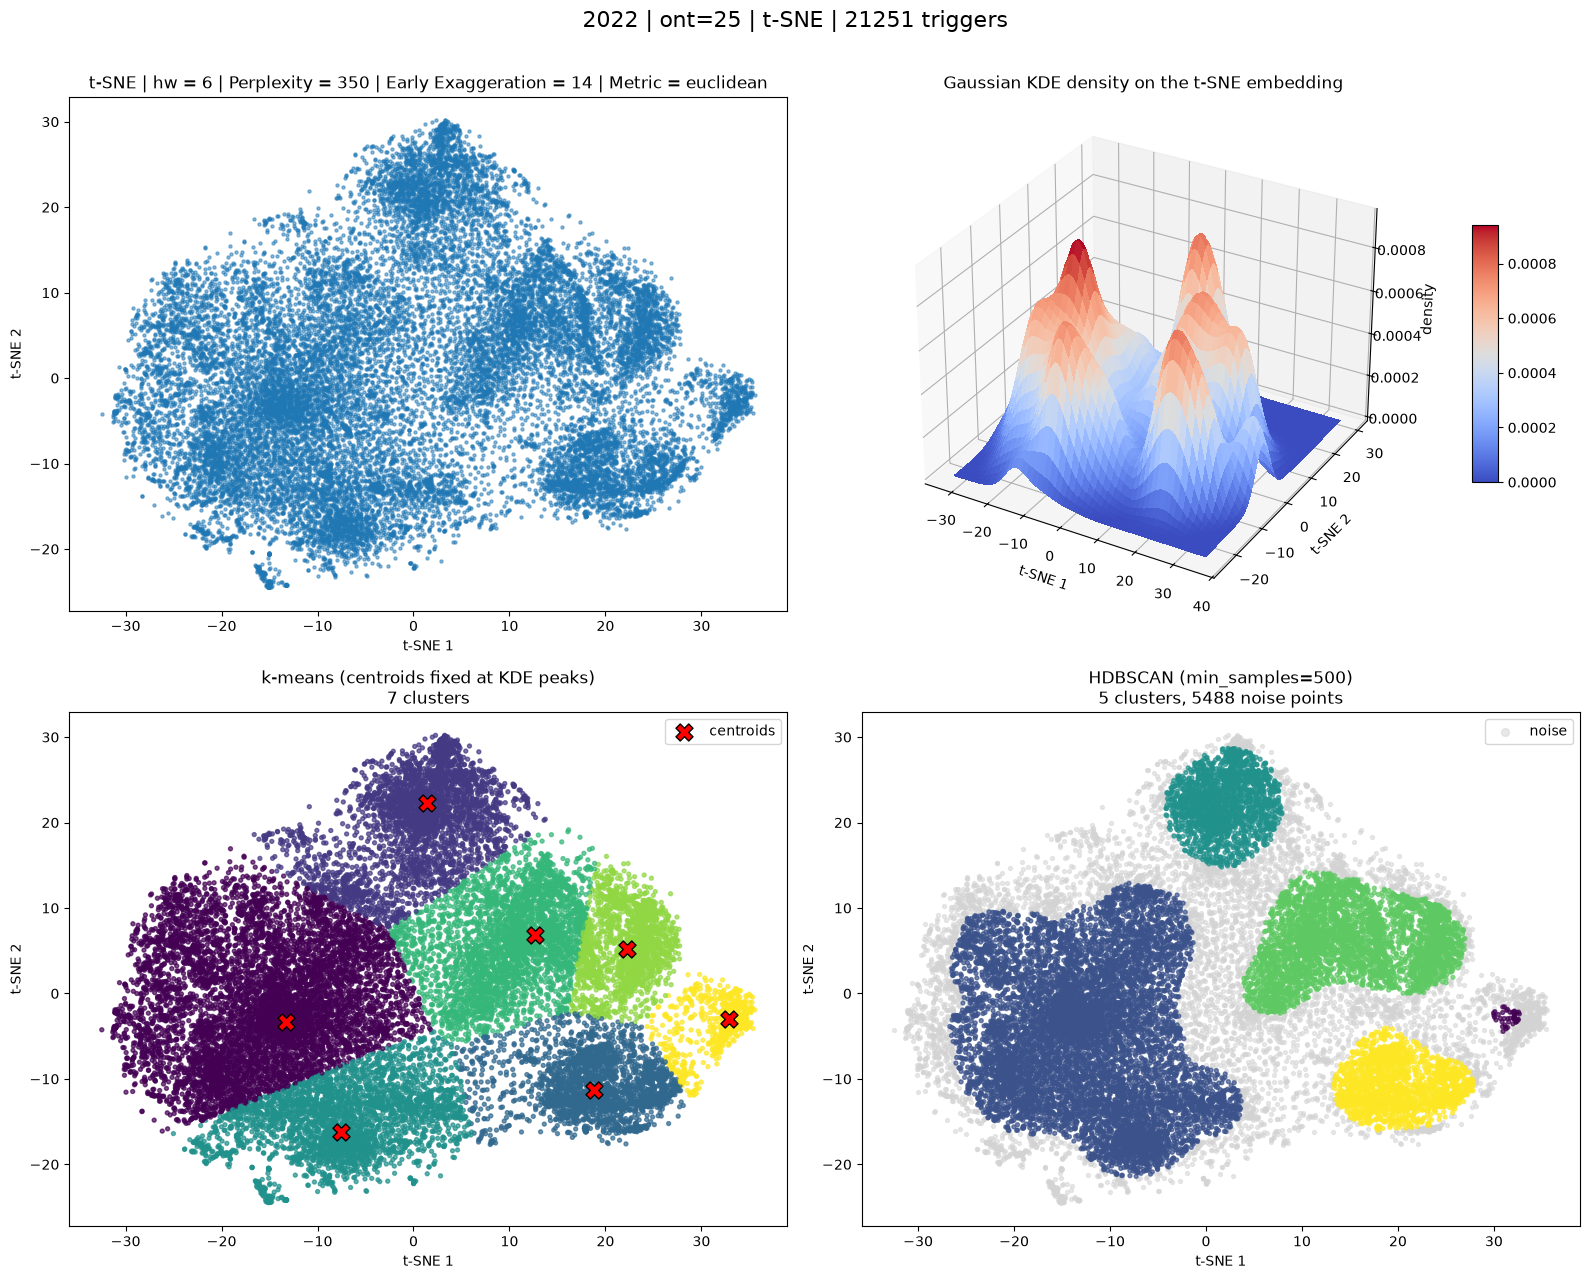

2022 ont=25 t-SNE: k-means 7 clusters, HDBSCAN 5 clusters / 5488 noise


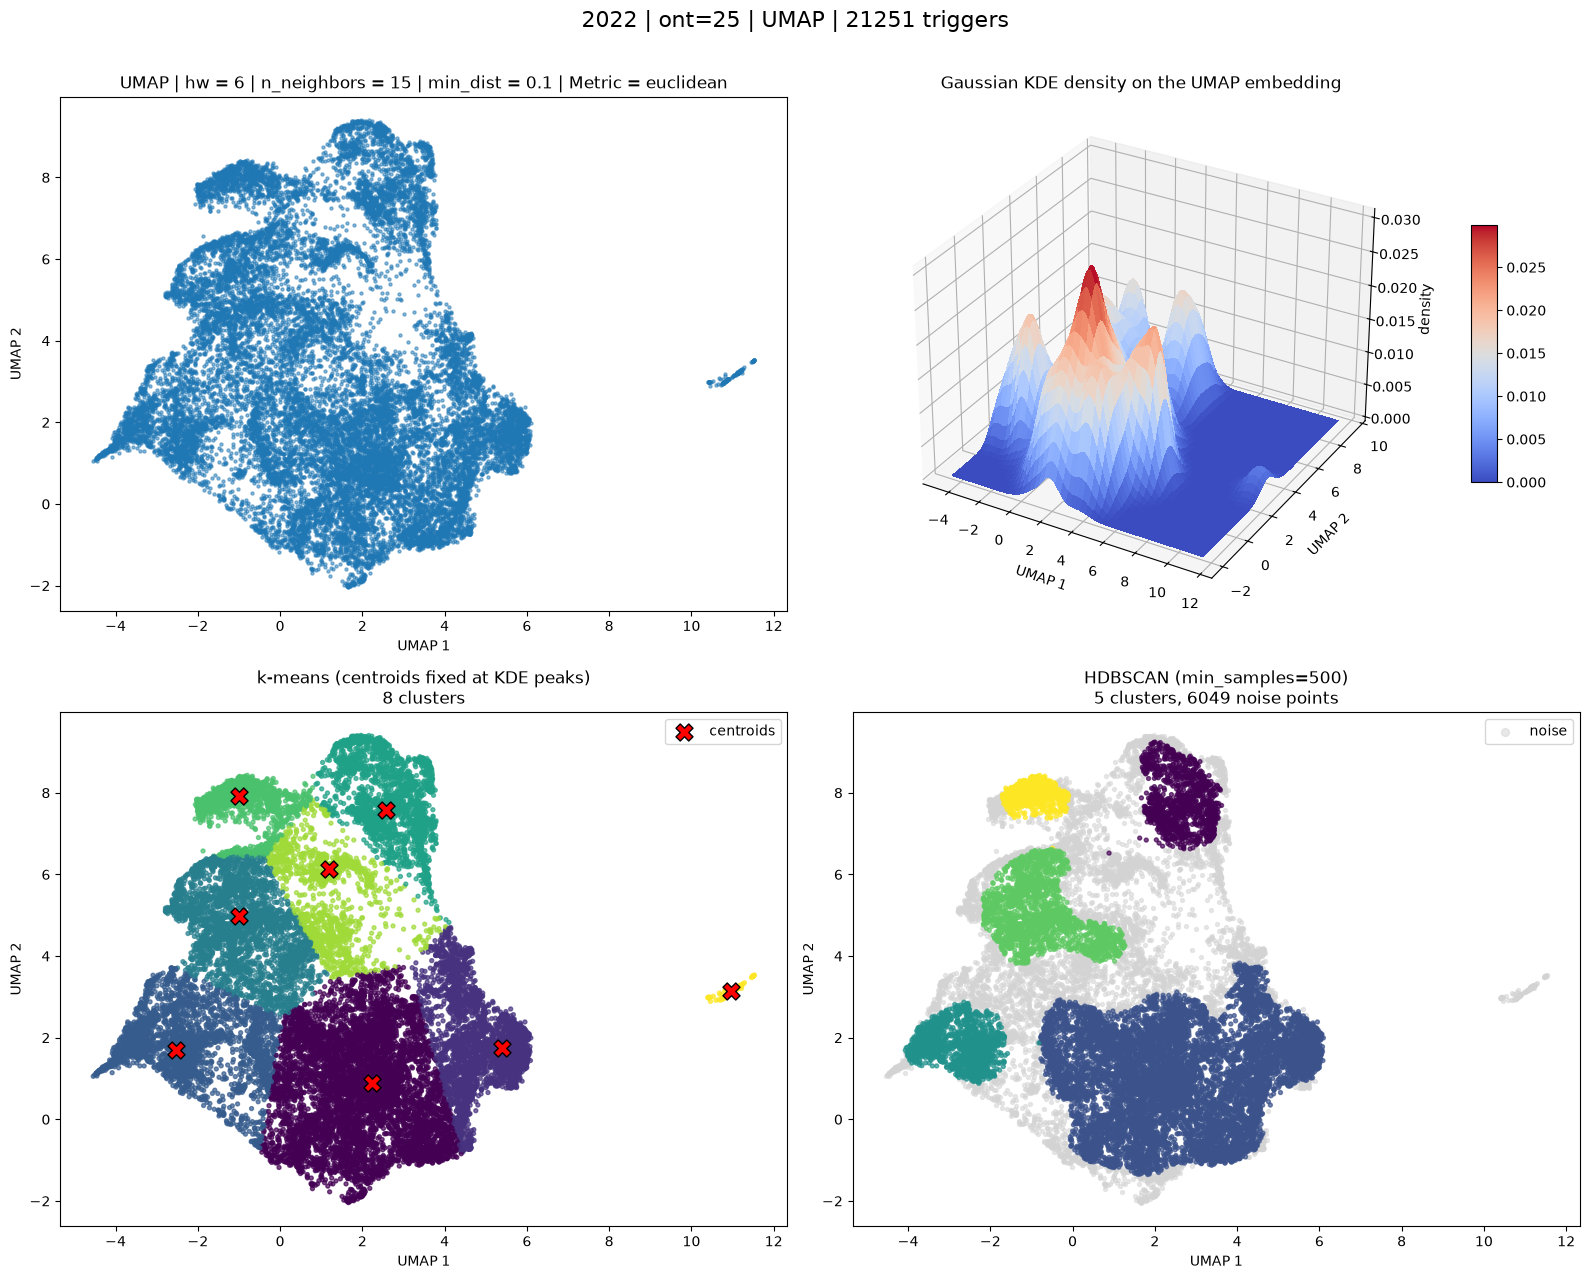

2022 ont=25 UMAP: k-means 8 clusters, HDBSCAN 5 clusters / 6049 noise
2022 ont=25: t-SNE loaded from TERZ_hw12_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw12_ont25_2022_umap_nn15_md0.1.npy


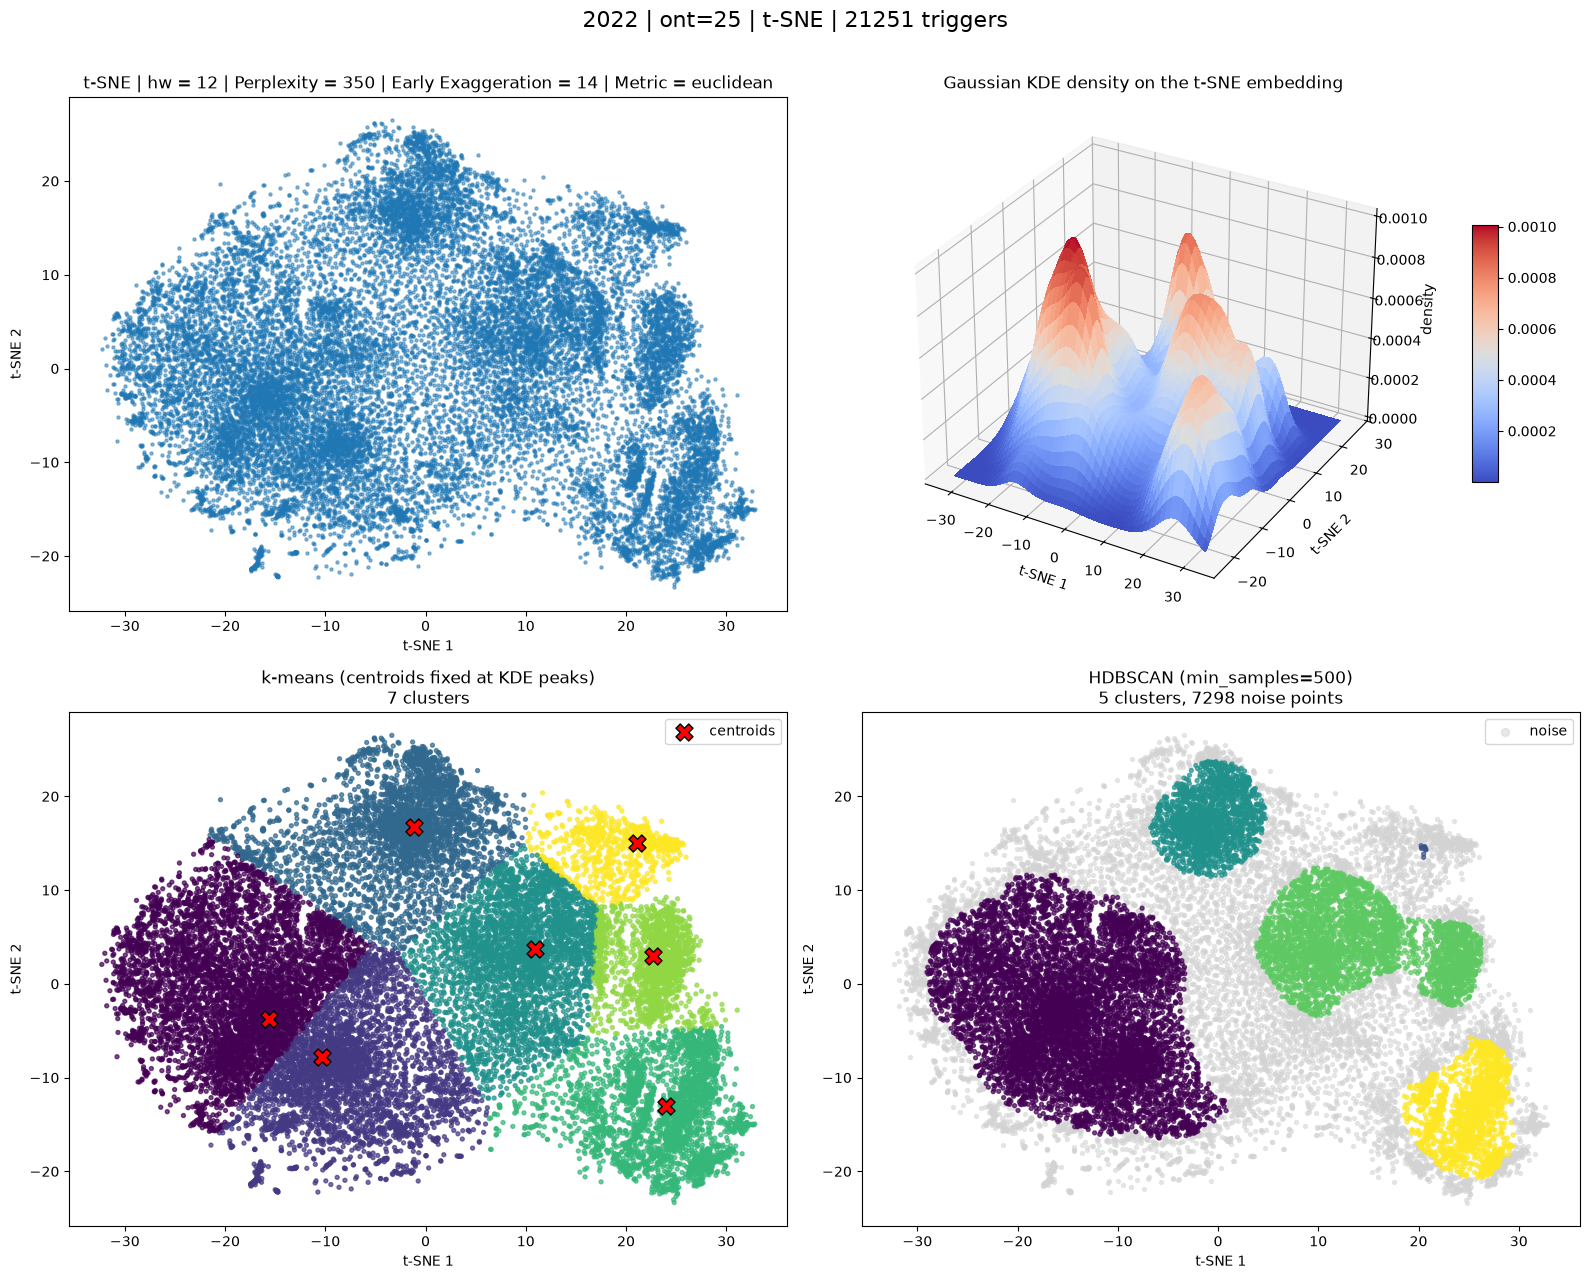

2022 ont=25 t-SNE: k-means 7 clusters, HDBSCAN 5 clusters / 7298 noise


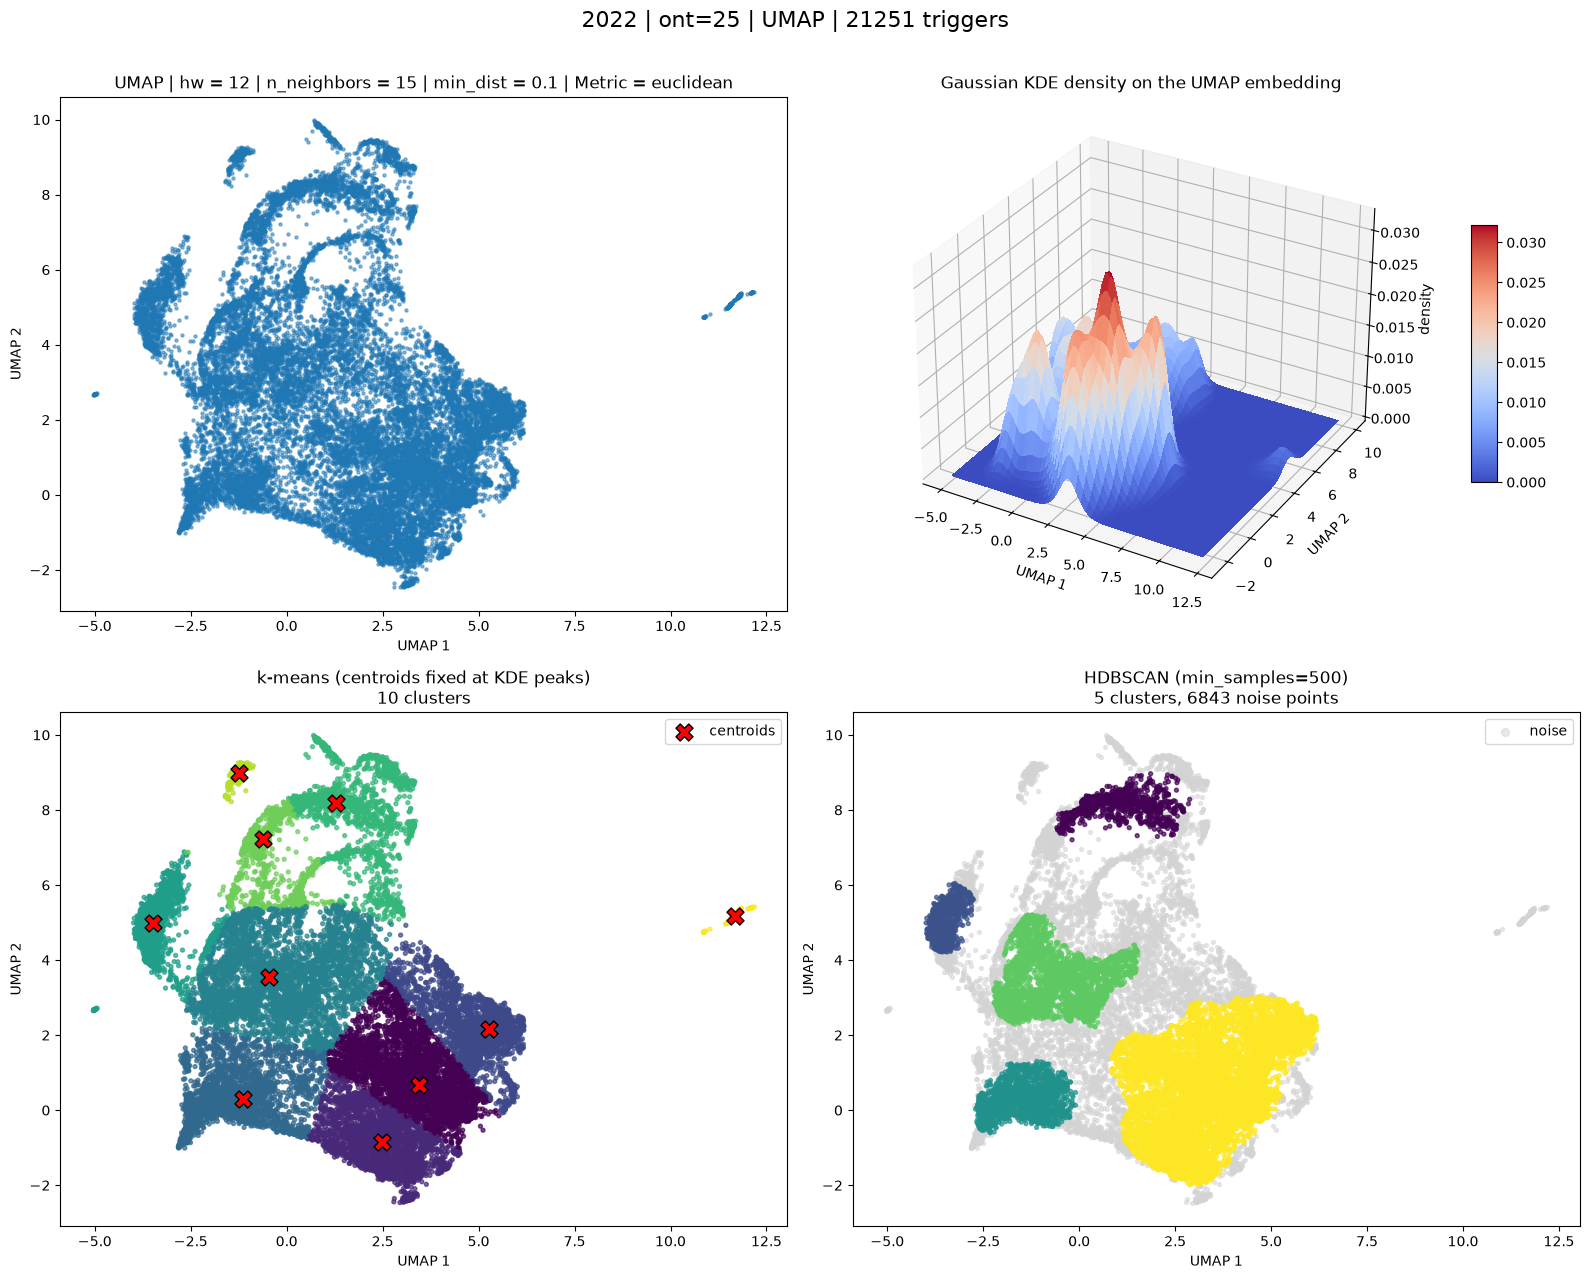

2022 ont=25 UMAP: k-means 10 clusters, HDBSCAN 5 clusters / 6843 noise


In [4]:
for year in YEARS:
    for ont in ONTS:
        for hw in HW:
            run(year, ont, hw)

## Balanced subset and second embedding

For every dataset, the clusters of the `LABEL_FROM` projection are the labels. `LABEL_METHOD = "hdbscan"` (default) uses the HDBSCAN clusters of the 4th panel above (same `hdbscan_min_samples`, cached on disk so it is not recomputed); `"kmeans"` gives back the k-means clusters with centroids at the KDE peaks. HDBSCAN noise points (label -1) are left out unless `INCLUDE_NOISE = True`.

`PER_CLUSTER` triggers are drawn at random from every cluster (all of them if a cluster is smaller; this is printed), and t-SNE and UMAP are computed again on that subset. The features are normalised and standardised again using only the subset.

The selected row indices and labels are saved in `SUBSET_DIR` (`idx` = row positions in the parquet, `labels` = cluster of each selected row, `labels_full` = cluster of every row). The new embeddings are cached like the first ones; a cache file is ignored when the selection no longer matches. Colours are the first-round cluster labels, so the figure shows how well those clusters hold together in the new embedding.


In [5]:
METHOD_NAMES = {"hdbscan": "HDBSCAN", "kmeans": "k-means"}


def sampling_labels(E, proj, year, ont, hw):
    """Cluster label of every row of one embedding, same clustering as the panels above.
    LABEL_METHOD = "hdbscan" -> HDBSCAN labels (-1 = noise); "kmeans" -> k-means with centroids at the KDE peaks."""
    params = {**CLUSTER_PARAMS[proj], **CLUSTER_OVERRIDES.get((year, ont, proj), {})}
    if LABEL_METHOD == "hdbscan":
        labels = hdbscan_labels(E, params, year, ont, hw, proj)
        if not (labels >= 0).any():
            raise ValueError(f"HDBSCAN found no cluster (all noise) for {year} ont={ont} hw={hw}; "
                             f"lower hdbscan_min_samples (now {params['hdbscan_min_samples']}) in CLUSTER_PARAMS / CLUSTER_OVERRIDES.")
        return labels
    if LABEL_METHOD == "kmeans":
        X, Y, Z = density_surface(E)
        peaks, _ = kde_peaks(X, Y, Z, params["kde_peak_size"], params["kde_peak_min_rel"])
        labels, _ = kmeans_labels(E, peaks)
        return labels
    raise ValueError(f'LABEL_METHOD must be "hdbscan" or "kmeans", not {LABEL_METHOD!r}')


#def balanced_indices(labels, per_cluster):
#    """Sorted row indices: `per_cluster` random rows from every cluster (all rows if it has fewer).
#    HDBSCAN noise (label -1) is skipped unless INCLUDE_NOISE."""
#    rng = np.random.default_rng(RANDOM_STATE)
#    chosen = []
#    groups = np.unique(labels)
#    if not INCLUDE_NOISE:
#        groups = groups[groups >= 0]
#    for k in groups:
#        members = np.flatnonzero(labels == k)
#        if len(members) < per_cluster:
#            print(f"    cluster {k}: only {len(members)} triggers, taking all of them")
#        chosen.append(rng.choice(members, size=min(per_cluster, len(members)), replace=False))
#    return np.sort(np.concatenate(chosen))

def balanced_indices(labels, per_cluster, min_size):
    """Sorted row indices: `per_cluster` random rows from every cluster with at least `min_size` triggers (all rows
    if it has fewer than `per_cluster`); smaller clusters are discarded. HDBSCAN noise (label -1) is skipped unless INCLUDE_NOISE."""
    rng = np.random.default_rng(RANDOM_STATE)
    chosen = []
    groups = np.unique(labels)
    if not INCLUDE_NOISE:
        groups = groups[groups >= 0]
    for k in groups:
        members = np.flatnonzero(labels == k)
        if len(members) < min_size:
            print(f"    cluster {k}: only {len(members)} triggers (< {min_size}), discarded")
            continue
        if len(members) < per_cluster:
            print(f"    cluster {k}: only {len(members)} triggers, taking all of them")
        chosen.append(rng.choice(members, size=min(per_cluster, len(members)), replace=False))
    if not chosen:
        raise ValueError(f"Every cluster has fewer than MIN_CLUSTER_SIZE = {min_size} triggers; lower MIN_CLUSTER_SIZE.")
    return np.sort(np.concatenate(chosen))

def get_subset(year, ont, hw):
    """Balanced subset of one dataset -> (row indices, labels of those rows, labels of all rows)."""
    E = get_embeddings(year, ont, hw)[LABEL_FROM]
    labels_full = sampling_labels(E, LABEL_FROM, year, ont, hw)
    clusters = np.unique(labels_full[labels_full >= 0])
    print(f"{year} ont={ont} hw={hw}: {len(clusters)} {METHOD_NAMES[LABEL_METHOD]} clusters on the "
          f"{PROJECTIONS[LABEL_FROM]} embedding, sizes {np.bincount(labels_full[labels_full >= 0]).tolist()}, "
          f"{int((labels_full < 0).sum())} noise points{'' if INCLUDE_NOISE else ' (not sampled)'}")
    idx = balanced_indices(labels_full, PER_CLUSTER, MIN_CLUSTER_SIZE)
    np.savez(SUBSET_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_sub{PER_CLUSTER}_{LABEL_FROM}_{LABEL_METHOD}.npz",
             idx=idx, labels=labels_full[idx], labels_full=labels_full)
    return idx, labels_full[idx]


def subset_tsne(X_scaled):
    return TSNE(n_components=2, perplexity=SUB_PERPLEXITY, early_exaggeration=SUB_EARLY_EXAGGERATION,
                init="pca", learning_rate="auto", random_state=RANDOM_STATE,
                metric=METRIC).fit_transform(X_scaled)


def subset_umap(X_scaled):
    import umap
    return umap.UMAP(n_components=2, n_neighbors=SUB_UMAP_N_NEIGHBORS, min_dist=SUB_UMAP_MIN_DIST,
                     metric=METRIC, random_state=RANDOM_STATE).fit_transform(X_scaled)


SUBSET_COMPUTE = {"tsne": subset_tsne, "umap": subset_umap}


def subset_cache_path(year, ont, hw, projection):
    if projection == "tsne":
        tag = f"tsne_perp{SUB_PERPLEXITY}_ee{SUB_EARLY_EXAGGERATION}"
    else:
        tag = f"umap_nn{SUB_UMAP_N_NEIGHBORS}_md{SUB_UMAP_MIN_DIST}"
    return CACHE_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_sub{PER_CLUSTER}_{LABEL_FROM}_{LABEL_METHOD}_{tag}.npz"


def get_subset_embeddings(year, ont, hw, idx):
    """Return {"tsne": (m, 2), "umap": (m, 2)} for the rows `idx`; computes and caches whatever is missing."""
    paths = {proj: subset_cache_path(year, ont, hw, proj) for proj in SUBSET_COMPUTE}
    embeddings = {}
    for proj, path in paths.items():
        embeddings[proj] = None
        if path.exists():
            with np.load(path) as saved:
                if np.array_equal(saved["idx"], idx):          # the cached embedding belongs to this selection
                    embeddings[proj] = saved["embedding"]
                    print(f"{year} ont={ont} hw={hw}: subset {PROJECTIONS[proj]} loaded from {path.name}")

    missing = [proj for proj, E in embeddings.items() if E is None]
    if missing:
        X_scaled = feature_matrix(year, ont, hw, rows=idx)
        for proj in missing:
            print(f"{year} ont={ont} hw={hw}: computing subset {PROJECTIONS[proj]} ...")
            embeddings[proj] = SUBSET_COMPUTE[proj](X_scaled)
            np.savez(paths[proj], embedding=embeddings[proj], idx=idx)
    return embeddings


def label_colors(labels):
    """One colour per cluster label (same colours in the subset plot and the thumbnail map); noise is grey."""
    clusters = [k for k in np.unique(labels) if k >= 0]
    if len(clusters) <= 20:
        cmap = plt.get_cmap("tab10" if len(clusters) <= 10 else "tab20")
        colors = {k: cmap(i) for i, k in enumerate(clusters)}
    else:
        cmap = plt.get_cmap("gist_ncar")
        colors = {k: cmap(i / len(clusters)) for i, k in enumerate(clusters)}
    colors[-1] = "gray"
    return colors


def plot_subset(embeddings, labels, year, ont, hw):
    """One figure: t-SNE | UMAP of the balanced subset, coloured by the first-round cluster."""
    clusters = np.unique(labels)
    colors = label_colors(labels)
    titles = {
        "tsne": f"t-SNE | Perplexity = {SUB_PERPLEXITY} | Early Exaggeration = {SUB_EARLY_EXAGGERATION} | Metric = {METRIC}",
        "umap": f"UMAP | n_neighbors = {SUB_UMAP_N_NEIGHBORS} | min_dist = {SUB_UMAP_MIN_DIST} | Metric = {METRIC}",
    }

    fig, axes = plt.subplots(1, len(PROJECTIONS), figsize=(8 * len(PROJECTIONS), 7))
    for ax, (proj, name) in zip(np.atleast_1d(axes), PROJECTIONS.items()):
        E = embeddings[proj]
        for k in clusters:
            m = labels == k
            ax.scatter(E[m, 0], E[m, 1], s=6, alpha=0.6, color=colors[k],
                       label=f"{'noise' if k < 0 else f'cluster {k}'} (n={m.sum()})")
        ax.set_title(titles[proj], fontsize=10)
        ax.set_xlabel(f"{name} 1")
        ax.set_ylabel(f"{name} 2")
        ax.legend(loc="best", markerscale=3, fontsize=8)

    fig.suptitle(f"{year} | ont={ont} | hw = {hw} | {len(labels)} triggers, up to {PER_CLUSTER} per {METHOD_NAMES[LABEL_METHOD]} cluster "
                 f"(labels from {PROJECTIONS[LABEL_FROM]})", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_subset_{LABEL_METHOD}_{LABEL_FROM}labels.png", dpi=150)
    plt.show()
    plt.close(fig)


def run_subset(year, ont, hw):
    idx, labels = get_subset(year, ont, hw)
    embeddings = get_subset_embeddings(year, ont, hw, idx)
    plot_subset(embeddings, labels, year, ont, hw)


2022 ont=25: t-SNE loaded from TERZ_hw6_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw6_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=6: 5 HDBSCAN clusters on the t-SNE embedding, sizes [44, 8502, 1811, 3475, 1931], 5488 noise points (not sampled)
    cluster 0: only 44 triggers (< 750), discarded
2022 ont=25: 3000 triggers, 1230 features
2022 ont=25 hw=6: computing subset t-SNE ...
2022 ont=25 hw=6: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


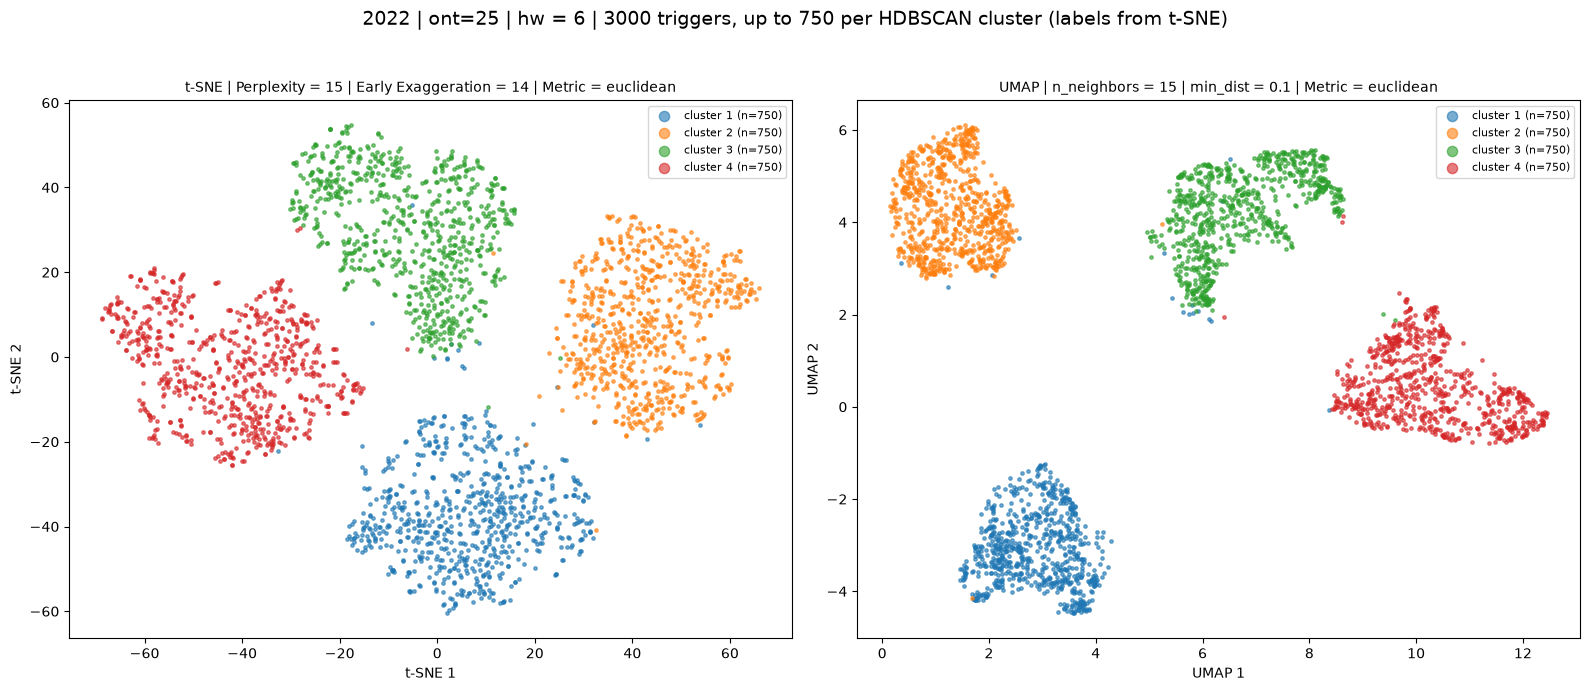

2022 ont=25: t-SNE loaded from TERZ_hw12_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw12_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=12: 5 HDBSCAN clusters on the t-SNE embedding, sizes [7242, 10, 1722, 3329, 1650], 7298 noise points (not sampled)
    cluster 1: only 10 triggers (< 750), discarded
2022 ont=25: 3000 triggers, 1230 features
2022 ont=25 hw=12: computing subset t-SNE ...
2022 ont=25 hw=12: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


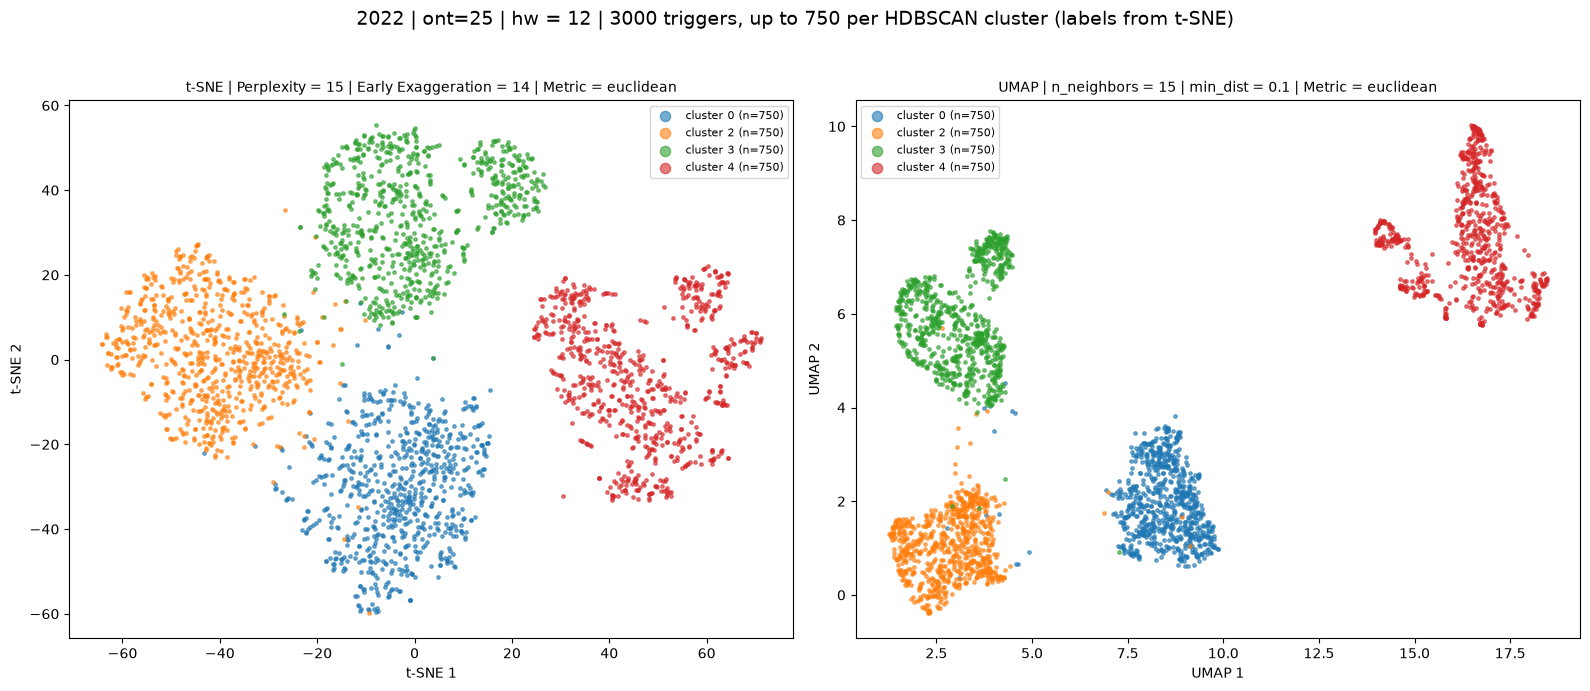

In [6]:
for year in YEARS:
    for ont in ONTS:
        for hw in HW:
            run_subset(year, ont, hw)

## Spectrogram map of the balanced subset

The same two subset embeddings, but every point is replaced by the spectrogram of its trigger (page `THUMB_PAGE` of its qtransform PDF), so you can see what each region and each cluster contains. Showing all the points would be an unreadable pile of images, so the plane is cut into a grid and, for every occupied cell, the trigger closest to the cell centre is shown (at most `N_THUMBS`). The frame colour is the first-round cluster, as in the figure above.

The parquet `file` column holds the day's mseed file, not the PDF, and the PDFs are named `qtransform_YYYYMMDD_NNNNNN.pdf` where `NNNNNN` is a per-day counter (0, 1, 2, ...), not a time. So the k-th trigger of a day is taken to be `qtransform_<date>_<k>.pdf`, with the triggers of a day numbered in parquet row order (`THUMB_ORDER = "parquet"`) or sorted by `THUMB_TIME_COLUMN` (`"time"`). For every dataset the cell prints how many triggers found a PDF and on how many days the number of PDFs equals the number of triggers (if PDFs or parquet rows are missing, the numbering is shifted and a warning is shown), plus two trigger -> PDF examples: open those PDFs and check that they show the trigger time printed next to them. Thumbnails are rendered once and cached in `THUMB_CACHE` (PyMuPDF is used if it is installed, otherwise `pdf2image`, which needs poppler). If the pages carry axes or a colourbar, use `THUMB_CROP` to keep only the image.


In [7]:
PDF_NAME_RE = re.compile(r"(\d{8})_(\d{6})")
_PDF_INDEX = {}                                           # root -> (sorted keys, paths); the search is slow on a big tree


def index_pdfs(root):
    """Every qtransform_YYYYMMDD_NNNNNN.pdf under `root` -> (keys, paths), sorted by key.
    key = (days since 1970-01-01) * 1_000_000 + NNNNNN, i.e. one number per (date, counter)."""
    root = Path(root)
    if root not in _PDF_INDEX:
        dates, counters, paths = [], [], []
        for p in root.rglob("*.pdf"):
            m = PDF_NAME_RE.search(p.name)
            if m:
                dates.append(m.group(1))
                counters.append(int(m.group(2)))
                paths.append(str(p))
        if not paths:
            around = sorted(q.name for q in root.parent.iterdir())[:15] if root.parent.exists() else "(folder does not exist)"
            raise FileNotFoundError(f"No PDF named like qtransform_YYYYMMDD_NNNNNN.pdf found under {root.resolve()}. "
                                    f"Set THUMB_PDF_ROOT. Next to it there is: {around}")
        day = pd.to_datetime(pd.Series(dates), format="%Y%m%d", errors="coerce")
        good = ~day.isna().to_numpy()
        if not good.any():
            raise ValueError(f"The dates in the PDF names under {root} are not YYYYMMDD, e.g. {Path(paths[0]).name}")
        days = day[good].to_numpy(dtype="datetime64[ms]").astype("int64") // 86400000
        keys = days * 1_000_000 + np.array(counters)[good]
        paths = np.array(paths)[good]
        order = np.argsort(keys, kind="stable")
        keys, paths = keys[order], paths[order]
        keep = np.r_[True, keys[1:] != keys[:-1]]          # same date + counter twice (e.g. in two subfolders): keep the first
        if not keep.all():
            print(f"  {int((~keep).sum())} PDFs share date and counter with another one, only the first is used")
        _PDF_INDEX[root] = (keys[keep], paths[keep])
        per_year = day[good].dt.year.value_counts().sort_index()
        print(f"indexed {int(keep.sum())} PDFs under {root} ({', '.join(f'{y}: {n}' for y, n in per_year.items())})")
    return _PDF_INDEX[root]


def trigger_meta(year, ont, hw):
    """Day (days since 1970-01-01) and time (UTC) of every trigger, in parquet row order."""
    path = PARQUET_DIR / f"TERZ_HHZ_hw{hw}_ont{ont}_{year}.parquet"
    try:
        import pyarrow.parquet as pq
        names = pq.read_schema(path).names
    except ImportError:
        names = list(pd.read_parquet(path).columns)
    for col in (THUMB_DATE_COLUMN, THUMB_TIME_COLUMN):
        if col not in names:
            raise ValueError(f"Column {col!r} not found in {path.name}. "
                             f"Non-feature columns: {[c for c in names if not c.startswith('feature_')]}")
    meta = pd.read_parquet(path, columns=[THUMB_DATE_COLUMN, THUMB_TIME_COLUMN])
    day = pd.to_datetime(meta[THUMB_DATE_COLUMN], format="ISO8601").to_numpy(dtype="datetime64[ms]").astype("int64") // 86400000
    time = pd.to_datetime(meta[THUMB_TIME_COLUMN], format="ISO8601")
    if time.dt.tz is not None:
        time = time.dt.tz_convert("UTC").dt.tz_localize(None)
    return pd.DataFrame({"day": day, "time": time.to_numpy()})


def trigger_pdfs(year, ont, hw):
    """Path of the qtransform PDF of every trigger in parquet row order ('' where there is none).
    The k-th trigger of a day (k = 0, 1, ...) is qtransform_<date>_<k:06d>.pdf."""
    pdf_keys, pdf_paths = index_pdfs(Path(str(THUMB_PDF_ROOT).format(year=year, ont=ont, hw=hw)))
    meta = trigger_meta(year, ont, hw)
    if THUMB_ORDER == "parquet":
        counter = meta.groupby("day").cumcount()
    elif THUMB_ORDER == "time":
        counter = meta.sort_values(["day", "time"], kind="stable").groupby("day").cumcount().reindex(meta.index)
    else:
        raise ValueError(f'THUMB_ORDER must be "parquet" or "time", not {THUMB_ORDER!r}')

    key = meta["day"].to_numpy() * 1_000_000 + counter.to_numpy()
    pos = np.clip(np.searchsorted(pdf_keys, key), 0, len(pdf_keys) - 1)
    ok = pdf_keys[pos] == key
    pdfs = np.where(ok, pdf_paths[pos], "")

    # sanity check: if the numbering follows the parquet rows, every day has as many PDFs as triggers
    n_trig = meta.groupby("day").size()
    n_pdf = pd.Series(pdf_keys // 1_000_000).value_counts().reindex(n_trig.index).fillna(0).astype(int)
    same = n_trig == n_pdf
    print(f"{year} ont={ont} hw={hw}: {int(ok.sum())} of {len(meta)} triggers have a PDF; "
          f"on {int(same.sum())} of {len(same)} days the number of PDFs equals the number of triggers")
    if not ok.any():
        dates = sorted(set(str(np.datetime64(int(d), 'D')) for d in n_trig.index))
        raise ValueError(f"No trigger found a PDF. The parquet has triggers on {dates[0]} ... {dates[-1]}; "
                         f"check that THUMB_PDF_ROOT contains PDFs of those dates (see the years listed above).")
    if same.mean() < 0.9:
        examples = [f"{np.datetime64(int(d), 'D')}: {n_trig[d]} triggers, {n_pdf[d]} PDFs" for d in n_trig.index[~same][:5]]
        print(f"  WARNING: many days have a different number of PDFs and triggers, so the PDF numbering may not follow "
              f"the parquet rows (e.g. {examples})")
    for i in range(min(2, len(meta))):
        print(f"  e.g. trigger at {meta['time'].iloc[i]} UTC -> {Path(pdfs[i]).name if ok[i] else 'no PDF'}")
    return pdfs


def render_pdf_page(pdf_path, page):
    """One page of a PDF as an RGB PIL image."""
    try:
        import fitz  # PyMuPDF
    except ImportError:
        from pdf2image import convert_from_path
        return convert_from_path(str(pdf_path), dpi=THUMB_DPI, first_page=page + 1, last_page=page + 1)[0].convert("RGB")
    with fitz.open(str(pdf_path)) as doc:
        pix = doc[page].get_pixmap(dpi=THUMB_DPI, alpha=False)
    return Image.frombytes("RGB", (pix.width, pix.height), pix.samples)


def get_thumbnail(pdf_path):
    """Thumbnail of one trigger as an (h, w, 3) uint8 array, or None if it has no PDF. Cached as PNG."""
    if not pdf_path:
        return None
    key = hashlib.md5(f"{pdf_path}|{THUMB_PAGE}|{THUMB_PX}|{THUMB_DPI}|{THUMB_CROP}".encode()).hexdigest()[:20]
    cached = THUMB_CACHE / f"{key}.png"
    if cached.exists():
        with Image.open(cached) as im:
            return np.asarray(im.convert("RGB"))

    pdf = Path(pdf_path)
    if not pdf.exists():
        return None
    img = render_pdf_page(pdf, THUMB_PAGE)
    if THUMB_CROP is not None:
        w, h = img.size
        left, top, right, bottom = THUMB_CROP
        img = img.crop((int(left * w), int(top * h), int(right * w), int(bottom * h)))
    img.thumbnail((THUMB_PX, THUMB_PX))
    img.save(cached)
    return np.asarray(img)


def grid_cells(n_thumbs):
    """Cells per side of the grid used to spread the thumbnails (about 1.5x as many cells as thumbnails)."""
    return int(np.ceil(np.sqrt(n_thumbs * 1.5)))


def spread_indices(E, n_thumbs, rng):
    """At most `n_thumbs` row indices spread evenly over the embedding: the point closest to the centre of every
    occupied grid cell (so the thumbnails sit on a regular lattice and barely overlap)."""
    n_cells = grid_cells(n_thumbs)
    lo = E.min(axis=0)
    u = (E - lo) / (E.max(axis=0) - lo) * n_cells            # coordinates in grid-cell units
    ij = np.clip(u.astype(int), 0, n_cells - 1)
    dist = np.hypot(*(u - (ij + 0.5)).T)                     # distance to the centre of its own cell
    cell = ij[:, 0] * n_cells + ij[:, 1]
    order = np.lexsort((dist, cell))                         # sorted by cell, then by distance to the centre
    _, first = np.unique(cell[order], return_index=True)     # first (= closest to the centre) point of every cell
    picked = order[first]
    if len(picked) > n_thumbs:
        picked = rng.choice(picked, size=n_thumbs, replace=False)
    return np.sort(picked)


def plot_thumbnail_map(E, pdfs, labels, proj, year, ont, hw):
    """Embedding drawn with the spectrogram of each (spread-out) trigger instead of a dot."""
    name = PROJECTIONS[proj]
    rng = np.random.default_rng(RANDOM_STATE)
    picked = spread_indices(E, N_THUMBS, rng)

    thumbs, missing = [], []
    for j in picked:
        img = get_thumbnail(pdfs[j])
        if img is None:
            missing.append(j)
        else:
            thumbs.append((j, img))
    if not thumbs:
        raise FileNotFoundError(f"None of the {len(picked)} selected triggers has a spectrogram PDF "
                                f"(THUMB_PDF_ROOT = {THUMB_PDF_ROOT!r}, THUMB_ORDER = {THUMB_ORDER!r}).")
    if missing:
        print(f"{name}: {len(missing)} of {len(picked)} selected triggers have no PDF, skipped")

    colors = label_colors(labels)
    fig, ax = plt.subplots(figsize=(THUMB_FIG_SIZE, THUMB_FIG_SIZE))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.94)
    cell_px = 0.96 * THUMB_FIG_SIZE * fig.dpi / grid_cells(N_THUMBS)      # grid cell side on screen, pixels
    zoom = THUMB_FILL * cell_px / (THUMB_PX * fig.dpi / 72)               # OffsetImage draws image pixels x zoom x dpi/72

    for j, img in thumbs:
        box = AnnotationBbox(OffsetImage(img, zoom=zoom), E[j], frameon=THUMB_BORDER, pad=0,
                             bboxprops=dict(edgecolor=colors[labels[j]], linewidth=1.5))
        ax.add_artist(box)

    pad = 0.5 * (E.max(axis=0) - E.min(axis=0)) / grid_cells(N_THUMBS)
    ax.set_xlim(E[:, 0].min() - pad[0], E[:, 0].max() + pad[0])
    ax.set_ylim(E[:, 1].min() - pad[1], E[:, 1].max() + pad[1])
    ax.axis("off")
    if THUMB_BORDER:
        handles = [Patch(facecolor="white", edgecolor=colors[k], linewidth=2,
                         label="noise" if k < 0 else f"cluster {k}") for k in np.unique(labels)]
        ax.legend(handles=handles, loc="upper left", fontsize=9)
    ax.set_title(f"{year} | ont={ont} | hw = {hw} | {name} of the balanced subset | {len(thumbs)} spectrograms "
                 f"(page {THUMB_PAGE}) of {len(labels)} triggers", fontsize=12)

    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_thumbs_{LABEL_METHOD}_{LABEL_FROM}labels_{proj}.png", dpi=150)
    plt.show()
    plt.close(fig)


def run_thumbnails(year, ont, hw):
    idx, labels = get_subset(year, ont, hw)
    embeddings = get_subset_embeddings(year, ont, hw, idx)
    pdfs = trigger_pdfs(year, ont, hw)[idx]
    for proj in PROJECTIONS:
        plot_thumbnail_map(embeddings[proj], pdfs, labels, proj, year, ont, hw)


2022 ont=25: t-SNE loaded from TERZ_hw6_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw6_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=6: 5 HDBSCAN clusters on the t-SNE embedding, sizes [44, 8502, 1811, 3475, 1931], 5488 noise points (not sampled)
    cluster 0: only 44 triggers (< 750), discarded
2022 ont=25 hw=6: subset t-SNE loaded from TERZ_hw6_ont25_2022_sub750_tsne_hdbscan_tsne_perp15_ee14.npz
2022 ont=25 hw=6: subset UMAP loaded from TERZ_hw6_ont25_2022_sub750_tsne_hdbscan_umap_nn15_md0.1.npz
indexed 64382 PDFs under TERZ_HHZ_ont25/TERZ_spectrograms_matrix_results_cut_hw6_ont25 (2022: 21251, 2023: 15582, 2024: 17356, 2025: 10193)
2022 ont=25 hw=6: 21251 of 21251 triggers have a PDF; on 363 of 363 days the number of PDFs equals the number of triggers
  e.g. trigger at 2022-06-09 15:27:49.040000 UTC -> qtransform_20220609_000000.pdf
  e.g. trigger at 2022-06-09 15:28:01.085000 UTC -> qtransform_20220609_000001.pdf


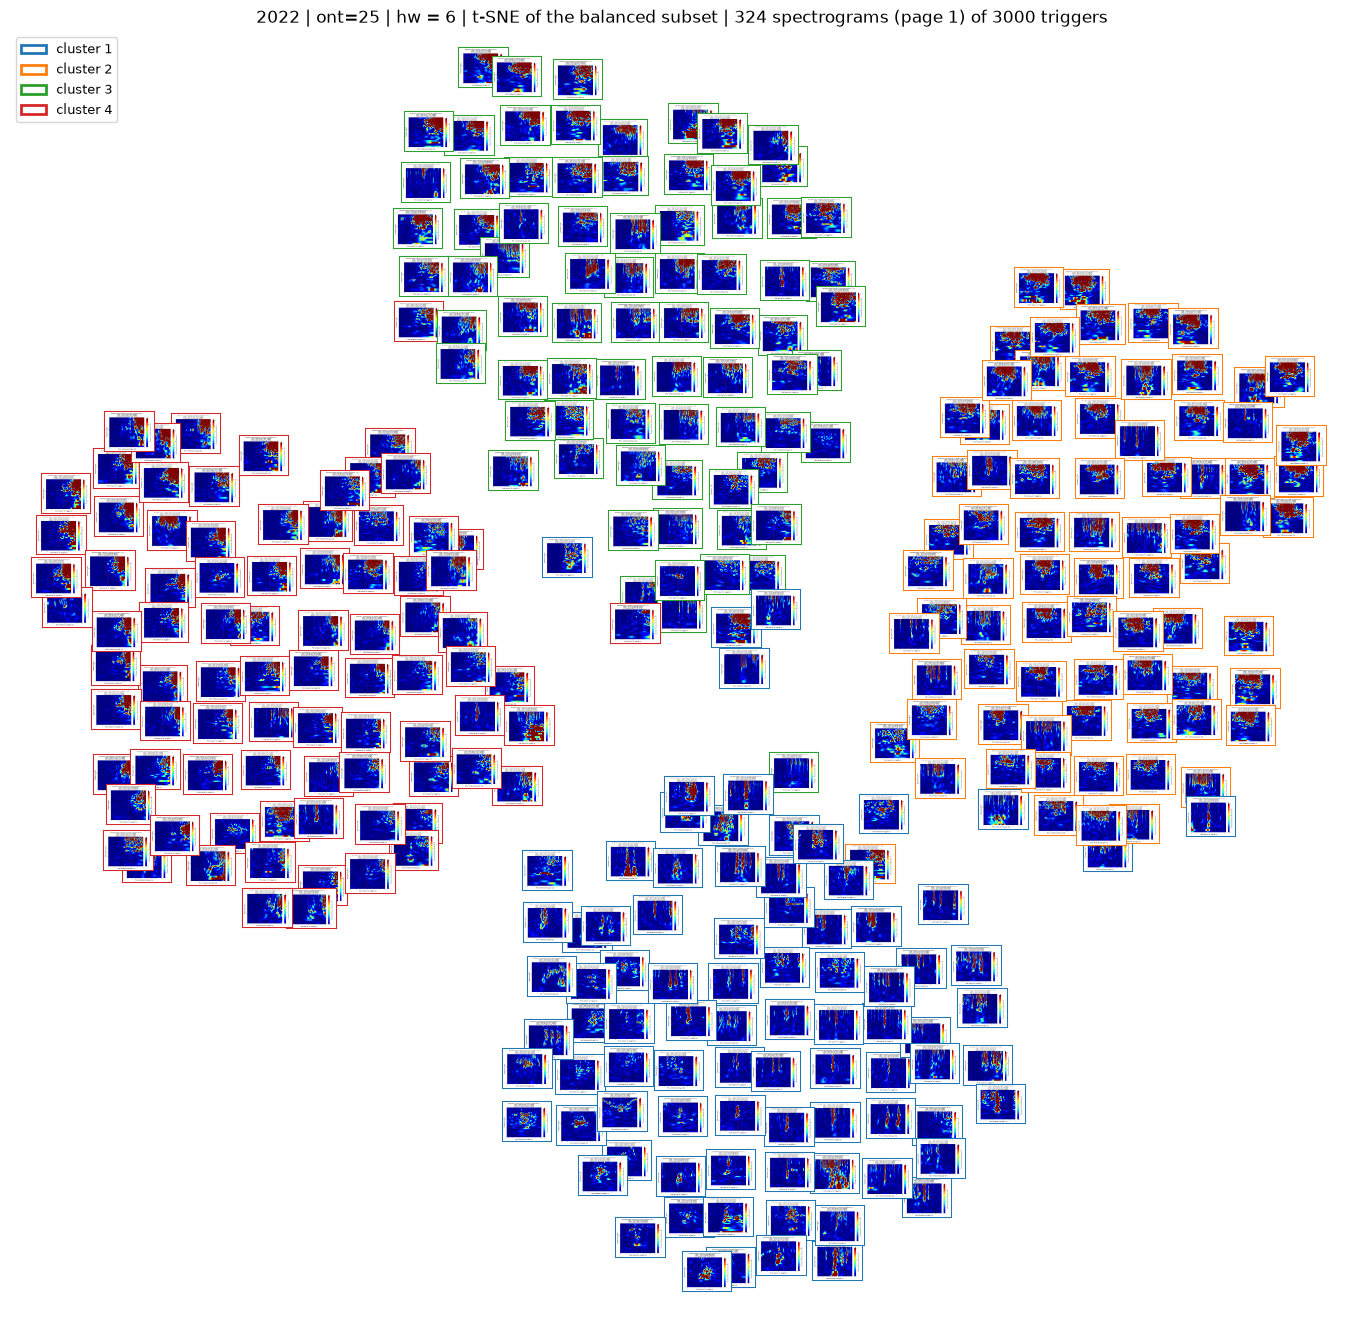

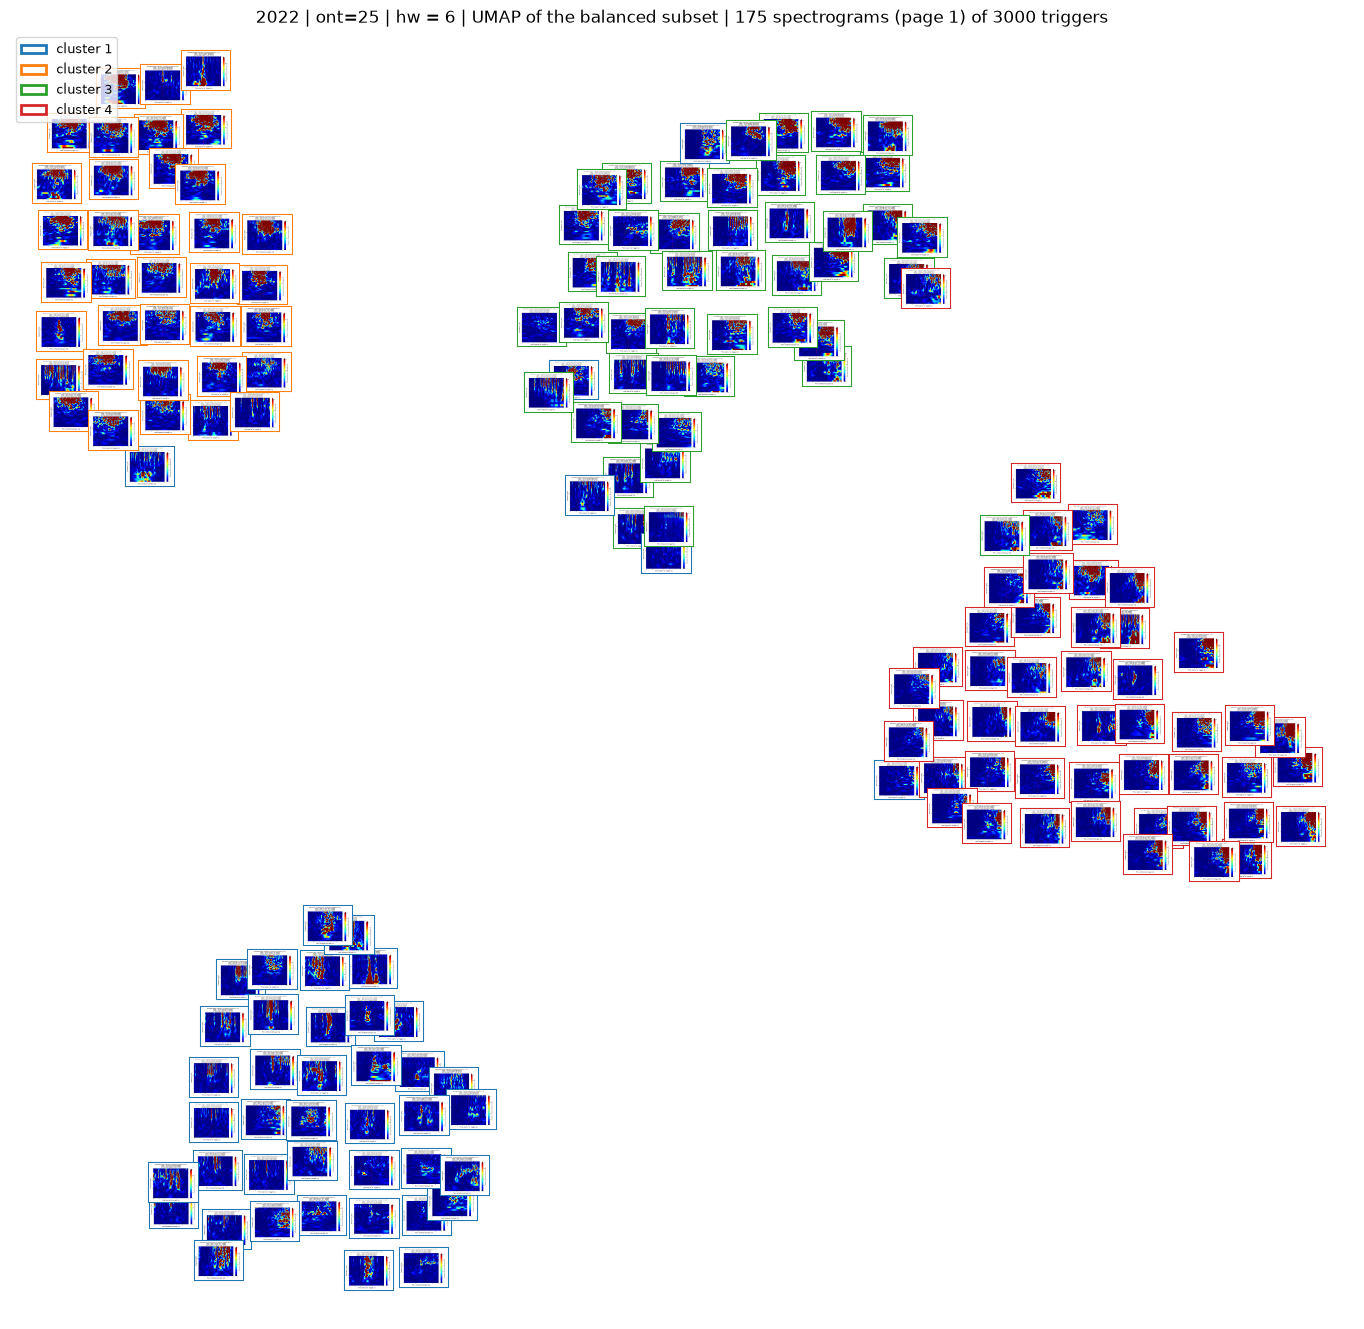

2022 ont=25: t-SNE loaded from TERZ_hw12_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw12_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=12: 5 HDBSCAN clusters on the t-SNE embedding, sizes [7242, 10, 1722, 3329, 1650], 7298 noise points (not sampled)
    cluster 1: only 10 triggers (< 750), discarded
2022 ont=25 hw=12: subset t-SNE loaded from TERZ_hw12_ont25_2022_sub750_tsne_hdbscan_tsne_perp15_ee14.npz
2022 ont=25 hw=12: subset UMAP loaded from TERZ_hw12_ont25_2022_sub750_tsne_hdbscan_umap_nn15_md0.1.npz
indexed 64382 PDFs under TERZ_HHZ_ont25/TERZ_spectrograms_matrix_results_cut_hw12_ont25 (2022: 21251, 2023: 15582, 2024: 17356, 2025: 10193)
2022 ont=25 hw=12: 21251 of 21251 triggers have a PDF; on 363 of 363 days the number of PDFs equals the number of triggers
  e.g. trigger at 2022-06-09 15:27:49.040000 UTC -> qtransform_20220609_000000.pdf
  e.g. trigger at 2022-06-09 15:28:01.085000 UTC -> qtransform_20220609_000001.pdf


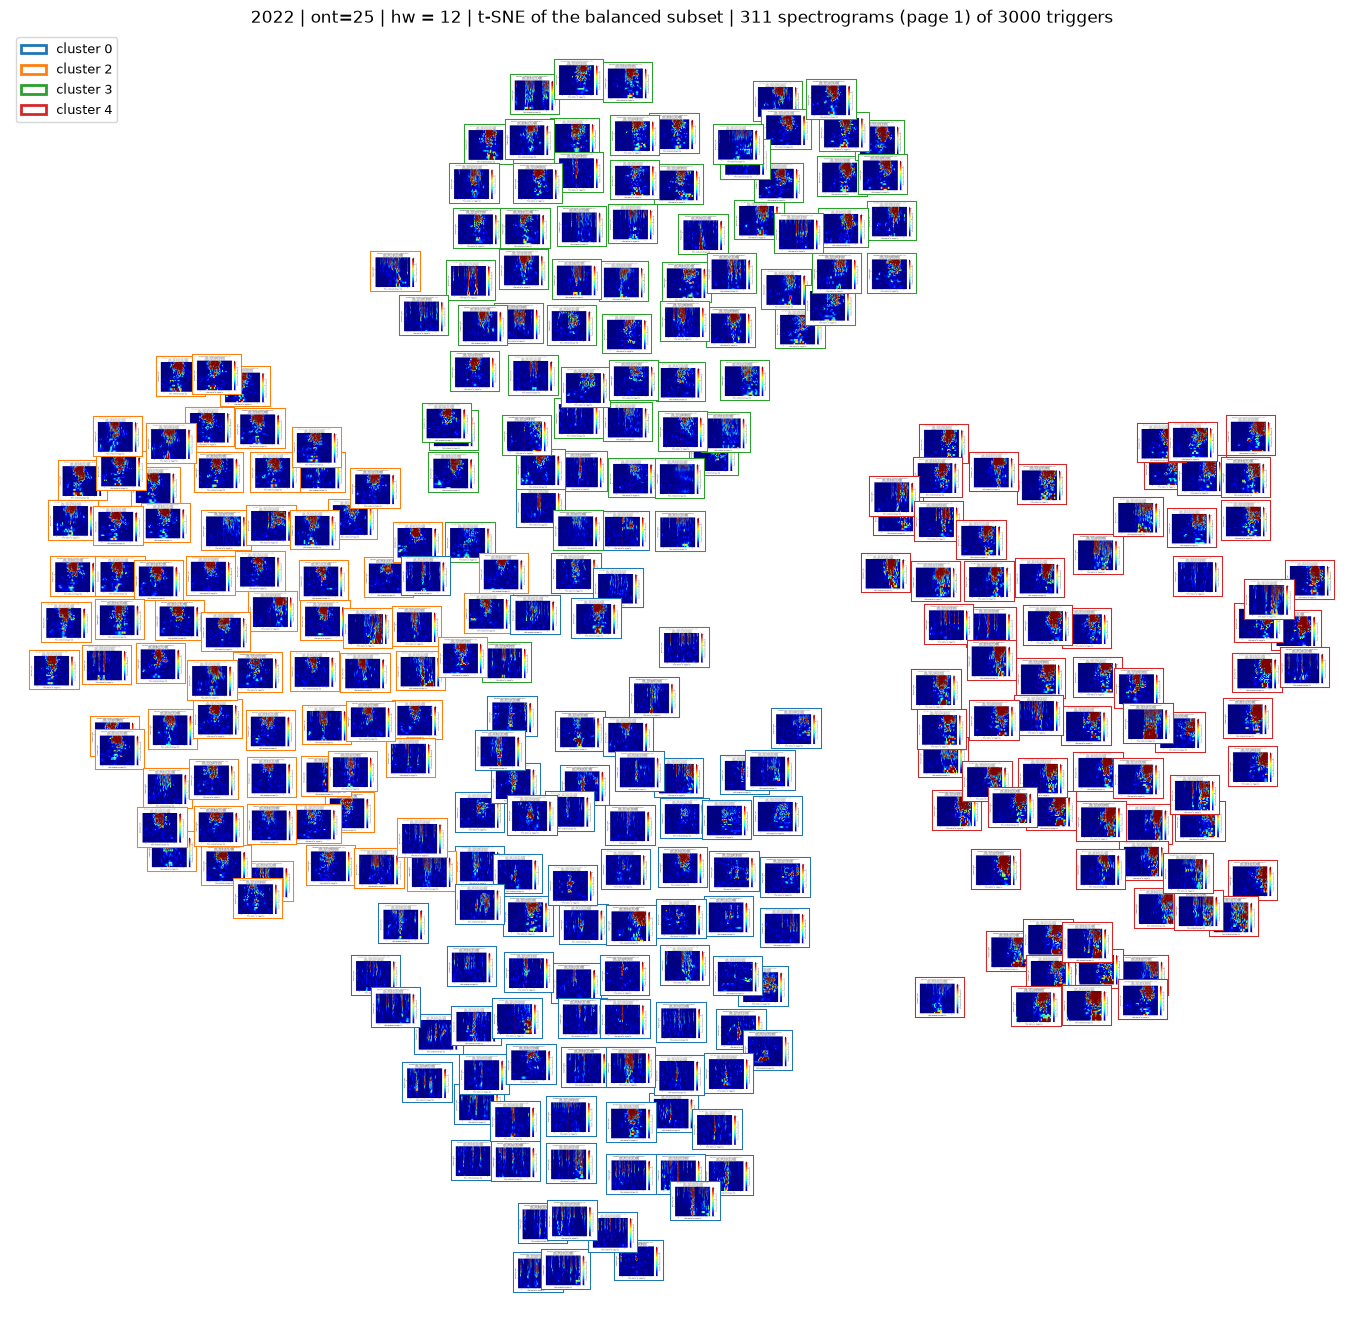

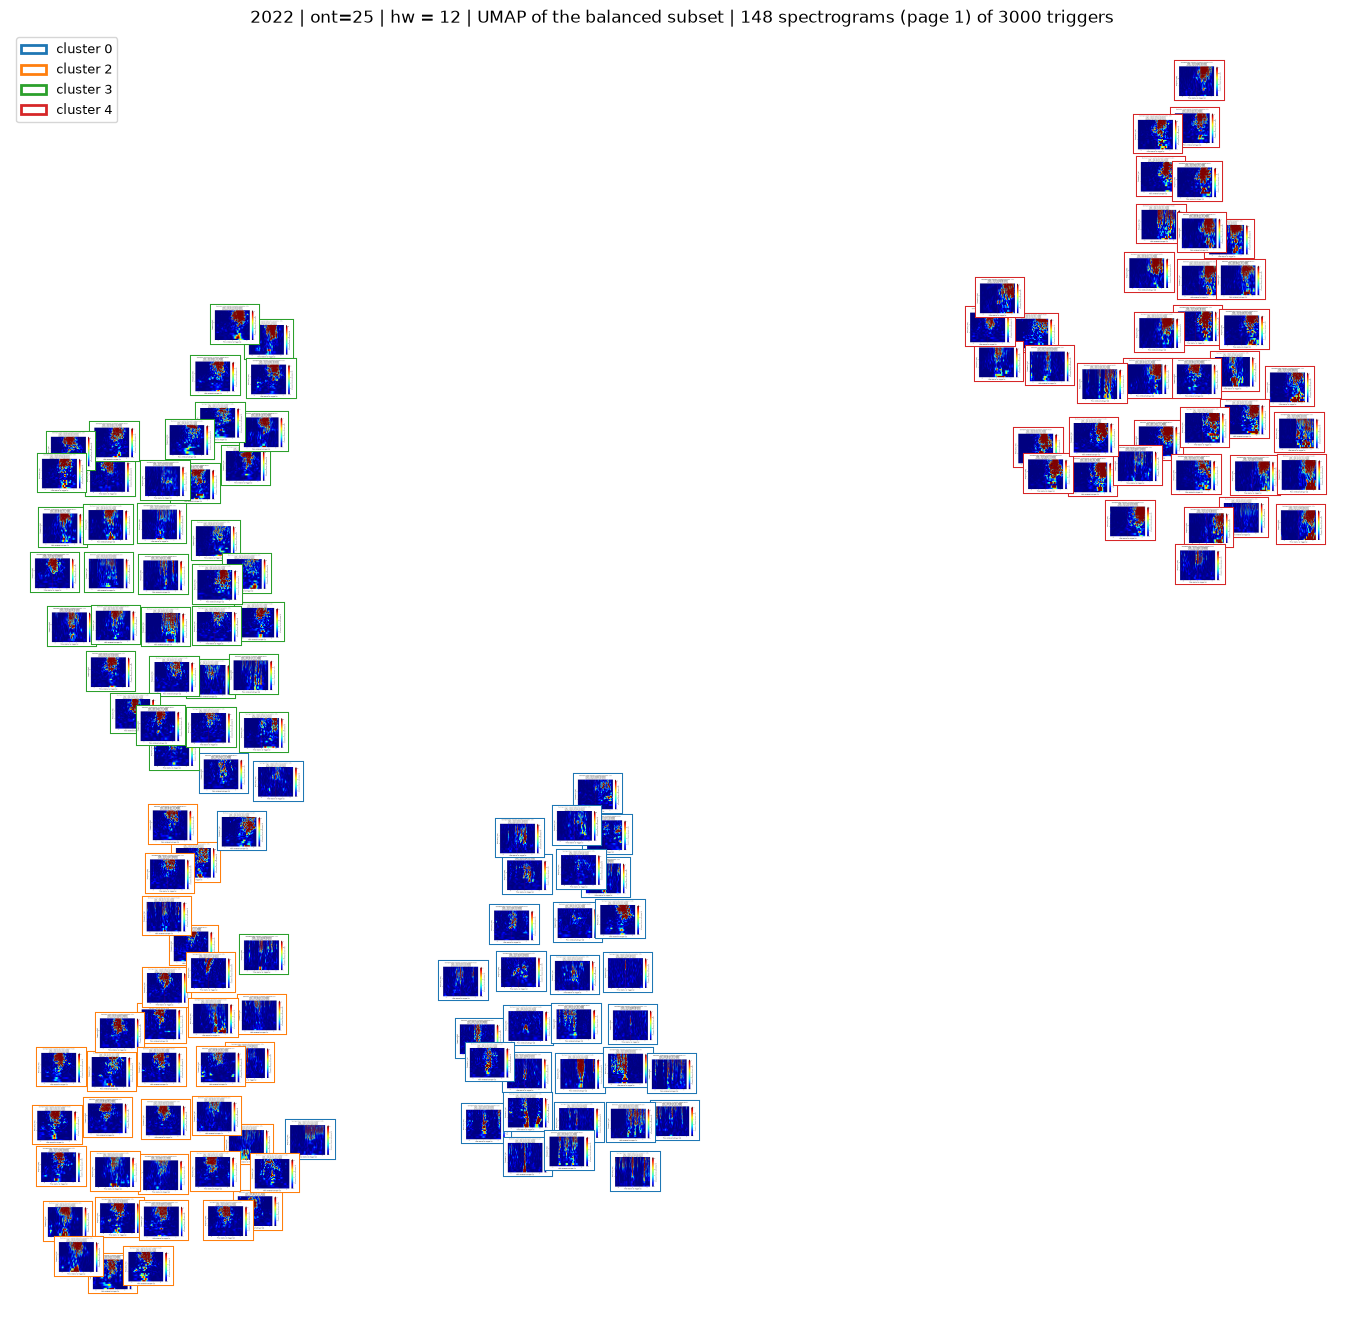

In [8]:
for year in YEARS:
    for ont in ONTS:
        for hw in HW:
            run_thumbnails(year, ont, hw)